[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L8/BA_L8_dsr/BA_L8_dsr.ipynb)

# BA_L8_dsr: How much does a search inflate the best Sharpe ratio?

*Quantlet of Lecture 8, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Expected best Sharpe ratio of N trading rules with no skill (Bailey and Lopez de Prado) and the deflated Sharpe ratio of the best of 810 moving-average and momentum rules for Bitcoin, selected on 2018-2022, as functions of N. EODHD daily data.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Left: the expected best annualised Sharpe ratio (SR) of $N$ rules with no skill,
$\mathrm{SR}_0 = \sqrt{V[\widehat{\mathrm{SR}}_n]}\,[(1-\gamma)\Phi^{-1}(1 - 1/N) + \gamma\,\Phi^{-1}(1 - 1/(Ne))]$, $\gamma \approx 0.5772$,
with the spread of the 810 in-sample SRs, against the SR of the winner. Right: the deflated Sharpe ratio $\mathrm{DSR} = \mathrm{PSR}(\mathrm{SR}_0)$
of the winner as a function of $N$. **How to read it**: the more rules are tried, the higher the bar a winner must clear.

Design: 810 rules (560 moving-average crossovers MA($s$, $l$), 250 momentum rules MOM($k$)), 10 bp cost per change of position,
selection on 2018–2022; daily Bitcoin closes from EODHD.

In [4]:
# the slide charts use 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10})
SLIDE_GOLD = '#B8860B'

END = pd.Timestamp('2026-10-23')                       # last day of the lecture sample
btc = pd.read_csv(data_file('market', 'BTC-USD.CC.csv'), parse_dates=['date']).set_index('date').loc[:END]
r = (100 * np.log(btc['close'])).diff().dropna().loc['2015-01-01':]           # daily log return, %
lv = np.log(btc['volume'].replace(0, np.nan)).diff().reindex(r.index).fillna(0)  # daily change of log volume
print(f'Bitcoin daily log returns: {len(r)} days, {r.index[0].date()} to {r.index[-1].date()}')

Bitcoin daily log returns: 4314 days, 2015-01-01 to 2026-10-23


In [5]:
from scipy import stats

COST = 0.10                                    # % per change of position (10 basis points)
S0, S1 = pd.Timestamp('2018-01-01'), pd.Timestamp('2022-12-31')
lc = np.log(btc['close'].loc['2016-01-01':END])
ret = 100 * lc.diff()
rules = [('MA', s_, l_) for s_ in range(2, 51, 2) for l_ in range(10, 251, 10) if l_ > s_ + 4] + [('MOM', k, 0) for k in range(1, 251)]


def signals(lcs):
    """Positions (1 = long, 0 = cash) of all rules; the position for day t is decided at the close of t-1."""
    ma = {w: lcs.rolling(w).mean() for w in set([x[1] for x in rules if x[0] == 'MA'] + [x[2] for x in rules if x[0] == 'MA'])}
    out = {}
    for typ, a_, b_ in rules:
        sig = (ma[a_] > ma[b_]) if typ == 'MA' else (lcs - lcs.shift(a_) > 0)
        out[(typ, a_, b_)] = sig.astype(float).shift(1)
    return pd.DataFrame(out)


def sharpe_mat(sig, rr):
    """Annualised Sharpe ratios and daily net returns (after costs) of all rules."""
    pos = sig.values
    g = pos * rr.values[:, None] - COST * np.abs(np.diff(np.vstack([np.zeros((1, pos.shape[1])), pos]), axis=0))
    return g.mean(0) / g.std(0, ddof=1) * np.sqrt(365), g


SIG = signals(lc)
isel, osel = (ret.index >= S0) & (ret.index <= S1), (ret.index > S1) & (ret.index <= END)
SR_in, G_in = sharpe_mat(SIG[isel].fillna(0), ret[isel])
SR_out, _ = sharpe_mat(SIG[osel].fillna(0), ret[osel])
best = int(np.nanargmax(SR_in))
bh_in = ret[isel].mean() / ret[isel].std() * np.sqrt(365)
bh_out = ret[osel].mean() / ret[osel].std() * np.sqrt(365)

# deflated Sharpe ratio, daily units
g = G_in[:, best]; T = len(g)
sr = g.mean() / g.std(ddof=1)
g3, g4 = stats.skew(g), stats.kurtosis(g, fisher=False)
Ntr, EM = len(rules), 0.5772156649
sr0 = np.sqrt(np.var(SR_in / np.sqrt(365), ddof=1)) * ((1 - EM) * stats.norm.ppf(1 - 1 / Ntr) + EM * stats.norm.ppf(1 - 1 / (Ntr * np.e)))
den = np.sqrt(1 - g3 * sr + (g4 - 1) / 4 * sr ** 2)
dsr = stats.norm.cdf((sr - sr0) * np.sqrt(T - 1) / den)
psr = stats.norm.cdf(sr * np.sqrt(T - 1) / den)

Winner: MOM(2); T = 1826 days, daily SR 0.0438 (annualised 0.84), skewness 0.58, kurtosis 11.46
Expected best annualised SR by chance: {2: 0.09, 10: 0.29, 100: 0.46, 810: 0.58}
DSR at N = 810: 0.72; PSR against zero: 0.97; DSR below 0.95 from N = 3


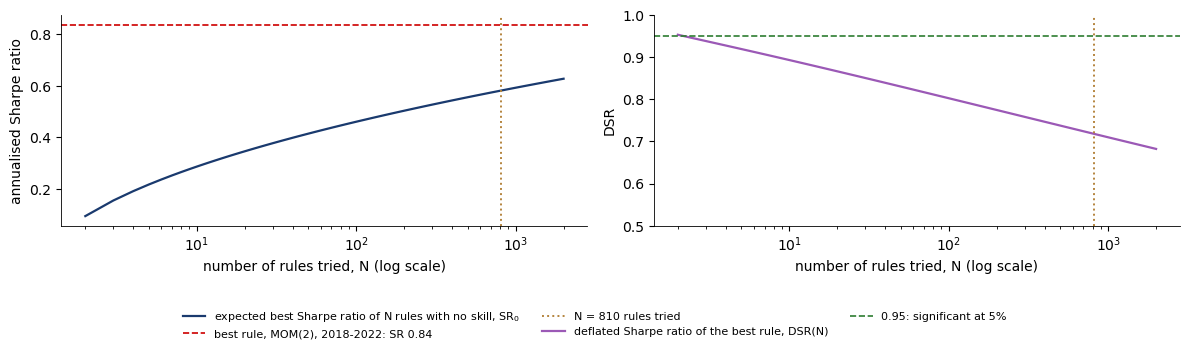

In [6]:
sd_sr = np.sqrt(np.var(SR_in / np.sqrt(365), ddof=1))
sr0_of = lambda N: sd_sr * ((1 - EM) * stats.norm.ppf(1 - 1 / N) + EM * stats.norm.ppf(1 - 1 / (N * np.e)))
dsr_of = lambda N: stats.norm.cdf((sr - sr0_of(N)) * np.sqrt(T - 1) / den)
Ns = np.unique(np.round(np.logspace(np.log10(2), np.log10(2000), 120)).astype(int))
typ, a_, b_ = rules[best]
print(f'Winner: {typ}({a_}' + (f', {b_})' if typ == 'MA' else ')') + f'; T = {T} days, daily SR {sr:.4f} (annualised {sr * np.sqrt(365):.2f}), '
      f'skewness {g3:.2f}, kurtosis {g4:.2f}')
print('Expected best annualised SR by chance:', {n_: round(float(sr0_of(n_) * np.sqrt(365)), 2) for n_ in [2, 10, 100, 810]})
print(f'DSR at N = 810: {dsr_of(810):.2f}; PSR against zero: {psr:.2f}; DSR below 0.95 from N = {Ns[np.argmax([dsr_of(n_) < 0.95 for n_ in Ns])]}')
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(Ns, [sr0_of(n_) * np.sqrt(365) for n_ in Ns], color=BLUE, lw=1.6, label='expected best Sharpe ratio of N rules with no skill, $\\mathrm{SR}_0$')
ax[0].axhline(sr * np.sqrt(365), color=RED, ls='--', lw=1.2, label=f'best rule, MOM(2), 2018-2022: SR {sr * np.sqrt(365):.2f}')
ax[0].axvline(810, color=GOLD, ls=':', lw=1.4, label='N = 810 rules tried')
ax[0].set_xscale('log'); ax[0].set_xlabel('number of rules tried, N (log scale)'); ax[0].set_ylabel('annualised Sharpe ratio')
ax[1].plot(Ns, [dsr_of(n_) for n_ in Ns], color=ETH, lw=1.6, label='deflated Sharpe ratio of the best rule, DSR(N)')
ax[1].axhline(0.95, color=GREEN, ls='--', lw=1.2, label='0.95: significant at 5%')
ax[1].axvline(810, color=GOLD, ls=':', lw=1.4)
ax[1].set_xscale('log'); ax[1].set_ylim(0.5, 1.0); ax[1].set_xlabel('number of rules tried, N (log scale)'); ax[1].set_ylabel('DSR')
fig.legend(loc='lower center', ncol=3, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.16, 1, 1))
save_fig(fig, 'ba_l8_dsr')